# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

## Phase 4 – Mitigation: a toy example

Phase 3 (`phase3_propagation`) found a gap in separation and sufficiency for the South, and no gap in independence.
Section 3.6 explains it: southern pairs sit closer to the cut, because many southern jobs require no skill that
separates the candidates, so any noise flips more southern decisions. Section 3.6.5 says what this means for a
mitigation of Adecco's system:

* there is nothing to train: the matcher is a formula with seven known weights (phase 1), so pre-processing and
  in-processing, which act on a training set and on a loss, have no place to act;
* post-processing the decisions for equalized odds ([Hardt et al. 2016](https://papers.neurips.cc/paper_files/paper/2016/file/6a9659feb1216f14f7384ba499518b38-Paper.pdf)) can only bring the North down to the South;
* C is not the truth: it holds what our extractors recovered, so there is no label to fit a mitigation on.

So the mitigation techniques cannot be applied to the real case. To show how they work we
build a toy case: one job opening, its candidates, and a matcher **learned from past decisions**, with
a known truth. The matcher does not read the region: it reads how far each candidate lives from the opening, as
Adecco's formula does with `Distance_match`, and the distance is a proxy of the region. Leaving the sensitive
attribute out of the model is called fairness through unawareness, and it is known to fail because of such proxies;
the toy shows why. We take one technique from each level of the mitigation taxonomy:

* **4.1** A toy hiring case: the candidates, the truth and the past decisions.
* **4.2** The baseline: a matcher learned from the past decisions.
* **4.3** Pre-processing: reweighing.
* **4.4** In-processing: a fairness penalty in the loss.
* **4.5** Post-processing: equalized odds.
* **4.6** Comparison.

Every decision is measured with the metrics of phase 3: the selection rate $r$ per
region with the SPD and DI of the South, $\text{SPD} = r_{\text{South}} - r_{\text{North}}$ and
$\text{DI} = r_{\text{South}} / r_{\text{North}}$ (independence), and the false negative and false positive rates
against the truth with the South's gaps (separation). The reference group is the North. The toy is a demonstration: its numbers say nothing about Adecco's data.

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


polars.config.Config

### 4.1 A toy hiring case

The toy is one job opening in the North, with many candidates: one row per candidate, as one list of the real case,
but with a hire or reject decision per candidate instead of a cut in the ranked list. Each candidate has:

* two scores, `skills` and `experience`, uniform in $[0, 1]$ and independent of the region; four candidates in ten
  are from the South;
* a `distance` from the opening, 0 next door and 1 far away. The opening is in the North, so northern candidates
  have a distance uniform in $[0, 0.6]$ and southern ones in $[0.4, 1]$: the distance tells the region, with some
  overlap;
* the truth, `hired_truth`: whether the two scores add up to more than 1, plus a little noise,

  $$\text{hired\_truth} = \bigl[\,\text{skills} + \text{experience} + \varepsilon > 1\,\bigr],
  \qquad \varepsilon \sim \mathcal{N}(0,\ 0.15^2).$$

  Without the noise, the two scores would predict the truth perfectly, the matcher would make no errors apart from the bias, and the mitigations would have nothing to trade off.
* the past decision, `hired_past`: what the recruiters decided in the past. They followed the truth, with one
  exception: 30% of the qualified southern candidates, drawn at random, were rejected. This is the only bias of the toy, and the matcher will learn
  from these decisions.

We draw a training set, from which the matcher learns, and a test set of the same size, on which every decision is
evaluated. The table gives, per region, the candidates of the training set and the share hired by the truth
and by the past decisions.

In [ ]:
from hiring_cv_bias.fairness.metrics import for_display
from hiring_cv_bias.fairness.mitigation import toy_candidates

N = 20_000
train = toy_candidates(N, seed=0)
test = toy_candidates(N, seed=1)
display(
    for_display(
        train.group_by("Location")
        .agg(
            pl.len().alias("candidates"),
            pl.col("hired_truth").mean(),
            pl.col("hired_past").mean(),
        )
        .sort("Location")
    )
)

Location,candidates,hired_truth,hired_past
"""NORTH""",12158,49.3,49.3
"""SOUTH""",7842,49.7,34.6


The truth hires half of the candidates in both regions, so a fair matcher would hire the two regions at the same
rate. The past decisions hire half of the North and a third of the South: the only difference between the regions is
the one we put in.

### 4.2 The baseline: a matcher learned from the past decisions

The matcher is a logistic regression on `skills`, `experience` and `distance`,

$$P(\text{hired}) = \sigma\bigl(\beta_0 + \beta_1\,\text{skills} + \beta_2\,\text{experience} + \beta_3\,\text{distance}\bigr),
\qquad \sigma(z) = \frac{1}{1 + e^{-z}},$$

and a candidate is hired when $P(\text{hired}) > 0.5$. It learns from the past decisions. The first table gives its coefficients. The second evaluates its decisions on the test set against the
truth: the accuracy, the selection rate per region with the South's SPD and DI, and the false negative and false
positive rates per region with the South's gaps.

In [ ]:
from hiring_cv_bias.fairness.mitigation import (
    coefficients_table,
    decide,
    design_matrix,
    fit_logistic,
    mitigation_table,
)

x, y = design_matrix(train), train["hired_past"].to_numpy().astype(float)
south = train["Location"].to_numpy() == "SOUTH"
models = {"baseline": fit_logistic(x, y)}
display(coefficients_table(models))
test = decide(test, models["baseline"], "baseline")
display(for_display(mitigation_table(test, ["baseline"]), ratios=["di"]))

term,baseline
"""intercept""",-6.31
"""skills""",6.56
"""experience""",6.64
"""distance""",-1.82


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6


The matcher learned the bias without seeing the region. The coefficient of `distance` is negative: a candidate who
lives far from the opening needs higher scores to be hired, although the truth ignores the distance. It learned
this because the qualified candidates with a wrong label are all from the South, and southern candidates live far. Against the truth, the
South is hired 9 points less than the North and its DI is at the 0.8 of the four-fifths rule: independence fails.
Separation fails too: the matcher misses three qualified southern candidates in ten, twice the North's share, and
hires fewer unqualified southern ones. In this case we have a model that repeats the bias of its
labels through a proxy and it is the opposite of phase 3, where independence held and only the error rates differed.

### 4.3 Pre-processing: reweighing

Reweighing ([Kamiran and Calders 2012](https://doi.org/10.1007/s10115-011-0463-8)) changes the training data, not the model. Every row gets the weight

$$w(a, y) = \frac{P(A = a)\,P(Y = y)}{P(A = a,\ Y = y)}$$

of its region $a$ and past label $y$. The weight compares how many candidates have that region and that label
with how many there would be if the region and the label were independent. A combination that occurs less often
than that, like the hired southern candidates, gets a weight above 1; one that occurs more often, like the rejected
southern candidates, gets a weight below 1. In the weighted data the region and the label are independent. The table gives
the four weights; the matcher is then trained again with them.

In [ ]:
from hiring_cv_bias.fairness.mitigation import reweighing_weights, row_weights

weights = reweighing_weights(train)
display(for_display(weights, ratios=["weight"]))
models["reweighing"] = fit_logistic(x, y, weights=row_weights(train, weights))
test = decide(test, models["reweighing"], "reweighing")
display(for_display(mitigation_table(test, ["baseline", "reweighing"]), ratios=["di"]))

Location,hired_past,p_group,p_label,p_joint,weight
"""NORTH""",true,60.8,43.5,30.0,0.88
"""NORTH""",false,60.8,56.5,30.8,1.11
"""SOUTH""",true,39.2,43.5,13.6,1.26
"""SOUTH""",false,39.2,56.5,25.7,0.86


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""reweighing""",87.5,45.1,40.4,-4.7,0.9,16.4,24.0,7.5,6.6,3.7,-3.0


The hired southern candidates weigh 1.26 and the rejected ones 0.86; the North moves the other way, by less. The
retrained matcher halves the gap: the South's SPD goes from −9.4 to −4.7 points, its DI from 0.8 to 0.9, and the
gaps in the two error rates halve too. The accuracy against the truth goes up, since the weights pull the matcher
away from the biased labels. The bias is reduced, not removed: the weights balance the label between the regions on
average, but the wrongly rejected candidates keep their wrong label, and the matcher still learns from them.

### 4.4 In-processing: a fairness penalty in the loss

The Prejudice Remover ([Kamishima et al. 2012](https://doi.org/10.1007/978-3-642-33486-3_4)) changes the model. It adds to the loss a fairness term, here $\lambda$
times the squared difference between the mean predicted probability of the two regions (the demographic parity term):

$$\mathcal{L}(\beta) = \text{cross-entropy}(\beta) + \lambda\,\bigl(\bar p_{\text{South}} - \bar p_{\text{North}}\bigr)^2,$$

where $\bar p_g$ is the mean of $P(\text{hired})$ over the candidates of region $g$. The trade-off parameter
$\lambda$ sets how much parity is worth in accuracy; we train with three values of it.

In [ ]:
PENALTIES = (1, 5, 20)
for penalty in PENALTIES:
    name = f"penalty_{penalty}"
    models[name] = fit_logistic(x, y, group=south, penalty=penalty)
    test = decide(test, models[name], name)
display(
    for_display(
        mitigation_table(test, ["baseline", *[f"penalty_{p}" for p in PENALTIES]]),
        ratios=["di"],
    )
)

method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""penalty_1""",86.9,45.0,38.8,-6.2,0.86,16.7,26.7,10.0,6.6,3.1,-3.5
"""penalty_5""",87.4,43.5,40.9,-2.5,0.94,18.4,23.1,4.7,5.4,3.8,-1.5
"""penalty_20""",87.4,42.8,42.0,-0.8,0.98,19.4,21.8,2.3,4.9,4.5,-0.4


The larger $\lambda$, the smaller the gap: with $\lambda = 20$ the two regions are hired at almost the same rate (SPD −0.8, DI 0.98)
and the two error gaps are within about two points. The accuracy does not fall, it rises a little,
because the bias of the labels is itself a difference between the regions. The penalty pushes the matcher away
from it. But the gap closes from both sides: the South's false negative rate falls from 30% to 22%, the North's rises
from 15% to 19%, and the North is now hired below the half that the truth hires in 4.1. The penalty asks for equal
rates, not for the truth.

### 4.5 Post-processing: equalized odds

The post-processing of [Hardt et al. 2016](https://papers.neurips.cc/paper_files/paper/2016/file/6a9659feb1216f14f7384ba499518b38-Paper.pdf) keeps the baseline matcher and changes its decisions at random: a hired
candidate stays hired with a probability `keep` and a rejected one becomes hired with a probability `add`, both per
region. After the flips, a region with true positive rate $\text{TPR}$ and false positive rate $\text{FPR}$ has

$$\text{TPR}' = \text{keep} \cdot \text{TPR} + \text{add} \cdot (1 - \text{TPR}),
\qquad \text{FPR}' = \text{keep} \cdot \text{FPR} + \text{add} \cdot (1 - \text{FPR}).$$

The two probabilities of each region are chosen by a linear program: the same $\text{TPR}'$ and the same
$\text{FPR}'$ in both regions, with the fewest expected errors. The rates are computed on the training set
against the truth: the method needs true labels, which the toy has and the real case has not. The table gives, per
region, the rates before and after the flips and the two probabilities.

In [ ]:
from hiring_cv_bias.fairness.mitigation import apply_flips, equalized_odds_flips

train = decide(train, models["baseline"], "baseline")
flips = equalized_odds_flips(train, "baseline")
display(for_display(flips, ratios=["keep", "add"]))
test = apply_flips(test, flips, "baseline", "equalized_odds")
display(
    for_display(mitigation_table(test, ["baseline", "equalized_odds"]), ratios=["di"])
)

group,pairs,tpr,fpr,keep,add,tpr_after,fpr_after
"""NORTH""",12158,84.2,8.0,0.86,0.0,72.2,6.9
"""SOUTH""",7842,71.0,2.8,1.0,0.04,72.2,6.9


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""equalized_odds""",82.8,40.0,39.6,-0.4,0.99,26.9,28.3,1.4,7.0,6.5,-0.5


A flip changes a decision without new information: among the rejected candidates of a region, the program cannot
tell the qualified from the others, so hiring some of them at random raises the true positive rate and the false
positive rate together. A region can only slide along the edge of its quadrilateral toward $(1, 1)$, never above
it. Here neither region's point lies inside the other's quadrilateral, so both move, unlike in section 3.6.5 where
the South stayed where it was. The South gains little: `keep` is 1 and `add` is 0.04, so it hires 4% of its
rejected candidates at random, and its true positive rate goes from 71% to 72% while its false positive rate goes
from 3% to 7%. The North pays: `add` is 0 and `keep` is 0.86, so it drops 14% of its hired candidates and its true
positive rate falls from 84% to 72%. On the test set the error rates of the two regions match within two points and
the SPD is within one. The cost: the accuracy falls to 83%, the lowest of the four decisions, and the North's false
negative rate almost doubles. This is still the leveling down of section 3.6.5, in a milder form: the only way to
equalize the rates is to make the better group worse, and the worse group gains a point. And the decisions are now
random: two identical candidates can get different outcomes.

### 4.6 Comparison

The table and the figure put the four decisions together, with $\lambda = 20$ for the penalty, the best of the three values of 4.4. The coefficients show what
the two retrained matchers changed.

term,baseline,reweighing,penalty_20
"""intercept""",-6.31,-6.95,-6.85
"""skills""",6.56,6.86,6.41
"""experience""",6.64,6.93,6.47
"""distance""",-1.82,-0.98,-0.25


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""reweighing""",87.5,45.1,40.4,-4.7,0.9,16.4,24.0,7.5,6.6,3.7,-3.0
"""penalty_20""",87.4,42.8,42.0,-0.8,0.98,19.4,21.8,2.3,4.9,4.5,-0.4
"""equalized_odds""",82.8,40.0,39.6,-0.4,0.99,26.9,28.3,1.4,7.0,6.5,-0.5


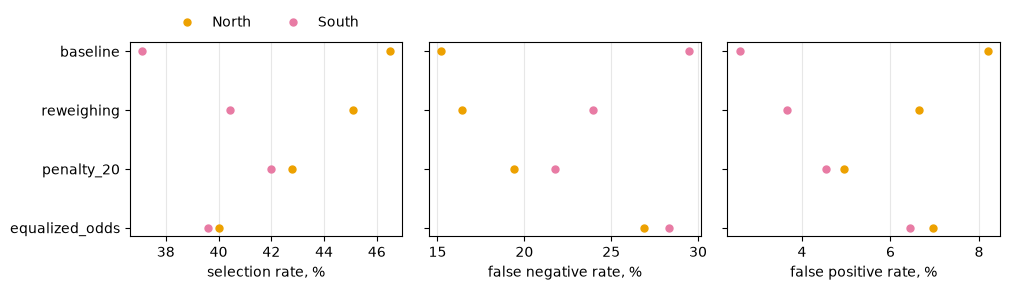

In [ ]:
from hiring_cv_bias.fairness.plots import plot_mitigation

METHODS = ["baseline", "reweighing", "penalty_20", "equalized_odds"]
display(coefficients_table({m: models[m] for m in METHODS if m in models}))
comparison = mitigation_table(test, METHODS)
display(for_display(comparison, ratios=["di"]))
plot_mitigation(comparison)
plt.show()

The coefficient of `distance` goes from −1.82 to −0.98 with reweighing and to −0.25 with the penalty. The two
retrained matchers rely less on the proxy, the penalty least of all.

The figure shows the trade-off. From top to bottom, the two dots of each row get closer. The South's rates move
toward the truth, the North's away from it.

The two retrained matchers gain accuracy. The bias is in the labels, and the truth is the same in both regions, so
a matcher that follows the labels less follows the truth more.

The penalty and the post-processing reach the same gaps, within about two points, but in opposite ways:

* the penalty retrains the matcher. The South's false negative rate falls from 30% to 22%, the North's rises from
  15% to 19%, and the accuracy rises;
* the post-processing keeps the matcher and flips its decisions. The South's false negative rate stays near 29%,
  the North's goes from 15% to 27%, and the accuracy falls by four points.

A mitigation that can change the model improves the worse group. One that can only touch the decisions lowers the
better one.

### Findings for the toy

* **Leaving the region out of the model does not help.** The matcher never reads the region, but it learns the bias
  of the past decisions through the distance from the opening, a proxy that the truth ignores: SPD −9 points, DI 0.8,
  three qualified southern candidates in ten missed against one and a half in the North (4.2). This is fairness
  through unawareness, and it fails.
* **Pre-processing: reweighing halves the gap** and improves the accuracy against the truth, without removing the
  bias: the matcher still reads the proxy (4.3, 4.6).
* **In-processing: the penalty closes the gap as far as $\lambda$ asks**, with no loss of accuracy here, by moving both
  regions: the South toward the truth, the North away from it (4.4).
* **Post-processing: equalized odds equalizes the rates exactly**, with the largest loss of accuracy: without
  new information it can only lower the North, give the South a point by hiring at random, and make every decision
  random (4.5, 4.6).
* **What this says about the real case.** The three techniques need what the toy has and Adecco's pipeline has not: a
  matcher that is trained, so that weights or a penalty can act on it (4.3, 4.4), and true labels, which the
  post-processing needs to compute its rates (4.5). In phase 3 the matcher is a fixed formula and C is not the truth.
  The only technique that could still be applied, the post-processing, would level the North down to the South, as
  section 3.6.5 shows on the real data and 4.5 on the toy.